In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [2]:
titanic = sns.load_dataset("titanic")


features = ["pclass","sex","fare","embarked","age"]
target = ["survived"]

imp_median = SimpleImputer(strategy = "median")
titanic[["age"]] = imp_median.fit_transform(titanic[["age"]]) 
imp_freq = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

le = LabelEncoder()
titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"]  = le.fit_transform(titanic["embarked"])

x = titanic[features]
y = titanic["survived"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42)


In [3]:
model = DecisionTreeClassifier()
model.fit(x_train,y_train)

y_pred_test = model.predict(x_test)
y_pred_train = model.predict(x_train)

print("Training accuracy:", accuracy_score(y_train, y_pred_train))
print("Testing Accuracy :", accuracy_score(y_test, y_pred_test))

Training accuracy: 0.9775280898876404
Testing Accuracy : 0.7653631284916201


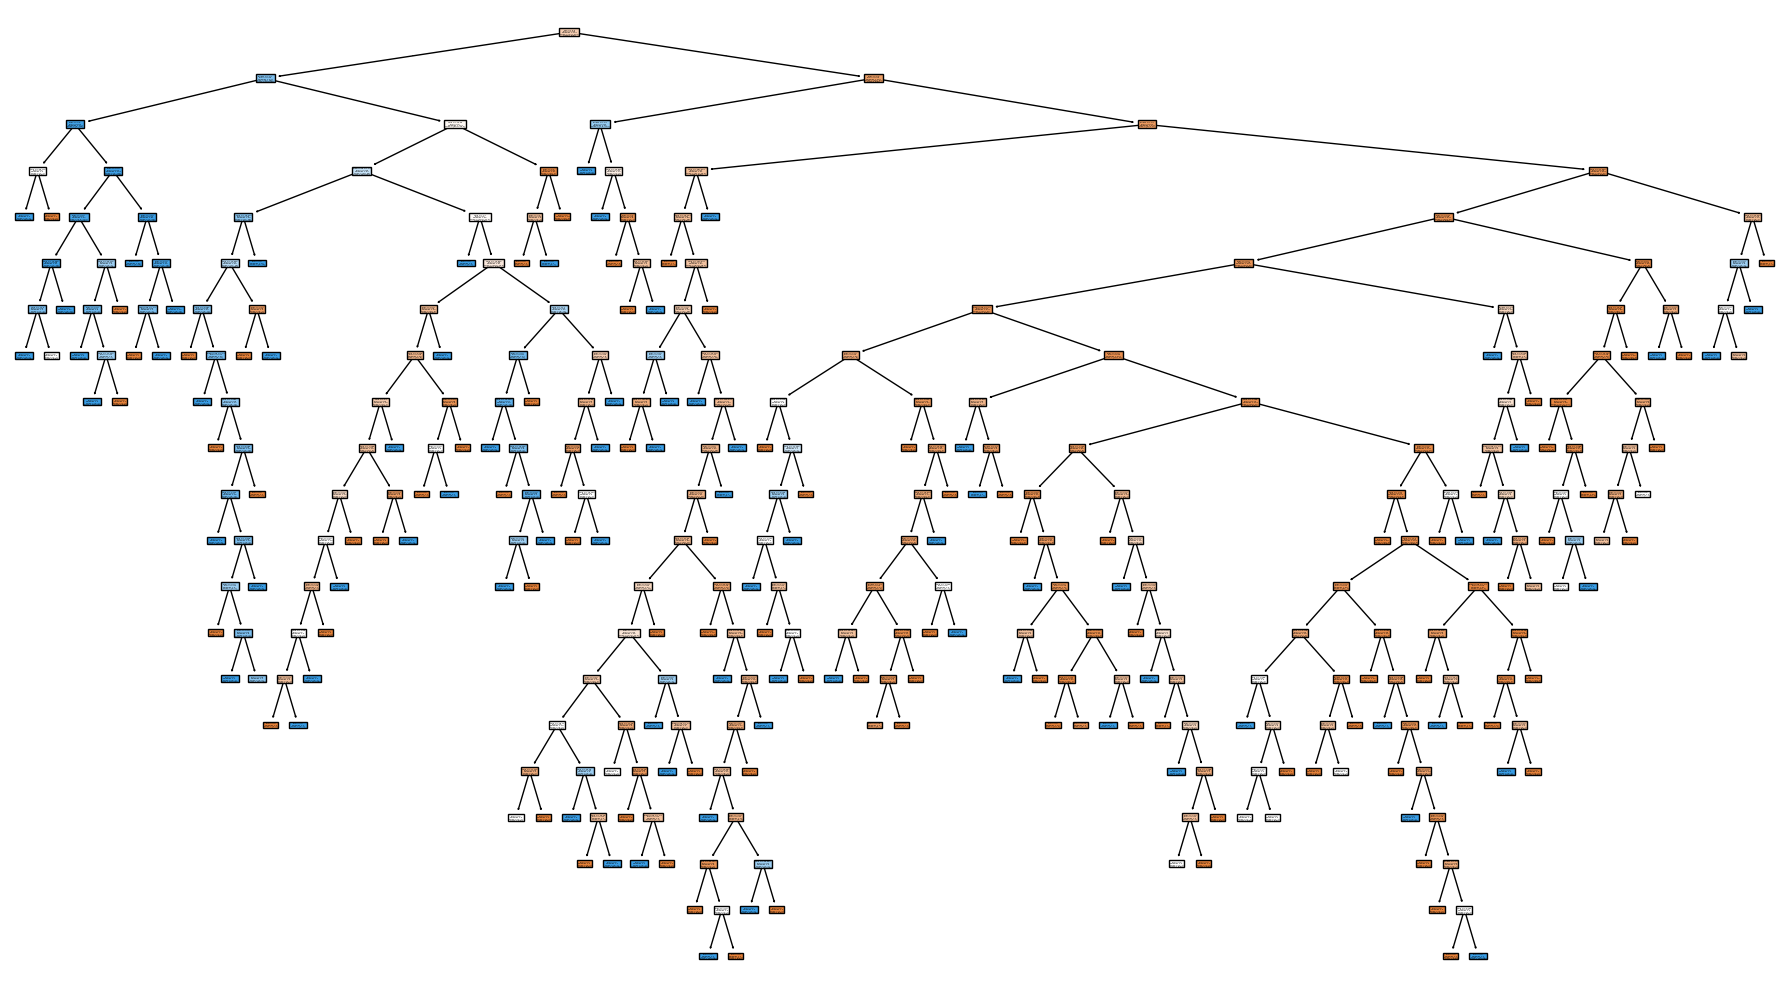

In [4]:
from sklearn.tree import plot_tree
plt.figure(figsize = (18,10))
plot_tree(
    model,
    feature_names = x.columns,
    class_names = ["Died","Survived"],
    filled = True
)
plt.tight_layout()

# Random Forest

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=501,
    oob_score= True,
    max_depth = 4
    
)
rf.fit(x_train, y_train)
y_pred = rf.predict(x_test)
print("Testing accuracy:", accuracy_score(y_test,y_pred))
print("OOB Score :",rf.oob_score_)

Testing accuracy: 0.8100558659217877
OOB Score : 0.824438202247191


# Bagging Classifier

In [6]:
from sklearn.ensemble import BaggingClassifier

base_model = DecisionTreeClassifier()

bagging = BaggingClassifier(
    base_model,
    n_estimators = 201
)

bagging.fit(x_train, y_train)
y_pred = bagging.predict(x_test)

print("Accuracy :", accuracy_score(y_test,y_pred))

Accuracy : 0.8044692737430168
